# Kinetic Monte Carlo model of MoS₂ flake growth

**Task:** CVD conversion of MoO₃ to MoS₂ on a triangular Mo lattice, simulated with
kinetic Monte Carlo. Code: `kmc/` (model), `run_experiments.py` (all results),
`make_report.py` (this notebook).

## 1. The model

* **Lattice.** 100×100 triangular lattice of Mo sites (6 neighbours each). Mo never moves;
  each site is either *oxide* or *MoS₂*, and only oxide → MoS₂ is allowed. The flake grows
  as a conversion front starting from **one converted site in the centre**.
* **Sulfur.** Every oxide site has 2 S slots (MoS₂ has 2 S per Mo).
* **Three events** at an oxide site that touches the flake (*n* = its number of MoS₂ neighbours):

| event | rate |
|---|---|
| S adsorption | $k_{ads}\,P\,(S_{max}-s)$, proportional to pressure |
| S desorption | $s\,\nu\,e^{-(E_{des}+n\,E_{bind})/kT}$, harder with more MoS₂ neighbours |
| conversion (only if $s = 2$) | $\nu\,e^{-(E_{conv}-n_\Delta\varepsilon_S-n_\nabla\varepsilon_{Mo})/kT}$ |

* **Two edge types without forcing a shape.** The 6 unit triangles around a site alternate
  between Δ and ∇ orientation. In 1H-MoS₂ the S columns sit over the Δ triangles only. A site joining
  an **S-terminated edge** closes a Δ triangle, so its bridging S is already there, which makes
  conversion easier ($\varepsilon_S$). A site joining a **Mo-terminated edge** closes a ∇ triangle
  ($\varepsilon_{Mo}$). Edges facing opposite directions are always of opposite type, so the
  six possible zigzag edges alternate S, Mo, S, Mo… The code only counts triangles and never mentions a
  shape.
* **kMC loop (BKL/Gillespie).** All event rates are kept in a binary sum tree. Each step picks one
  event with probability ∝ its rate (O(log N)), advances time by $\Delta t=-\ln u/R_{tot}$,
  and updates only the affected sites. There is no fixed time step.
* **Exact shortcut.** Sulfur far from the flake never affects anything, so it is not simulated. A site gets its
  steady-state sulfur (binomial with $\theta_0$) the moment it first touches the flake. An independent process
  that starts in steady state stays there, so this is exact.

### Parameters and why

| parameter | value | reasoning |
|---|---|---|
| $T$ | 1000 K | typical CVD temperature (650–850 °C) |
| $\nu$ | 1e+13 s⁻¹ | lattice-vibration attempt frequency |
| $k_{ads}$ | 100 Pa⁻¹s⁻¹ per slot | Hertz–Knudsen S₂ flux on one 8.6 Å² site ≈ 900 Pa⁻¹s⁻¹, sticking ≈ 0.1 |
| $E_{des}$ | 1.75 eV | weakly held S on oxide (≈ 65 µs); puts the growth threshold at 0.1–1 Pa |
| $E_{bind}$ | 0.25 eV / neighbour | ≈ one extra weak Mo–S bond; each neighbour keeps S 18× longer |
| $E_{conv}$ | 2.6 eV | bare sulfidation ≈ 1 s⁻¹, slow unless the site is embedded in the flake |
| $\varepsilon_S,\ \varepsilon_{Mo}$ | 0.3, 0.15 eV / triangle | S-edges join 5.7× faster, so Mo-edges bound the flake, as seen in S-rich CVD |
| growth window | 200 s | how long we watch. Growth slower than this counts as "stopped" |

## Q1. High sulfur pressure (10 Pa): a triangle grows

The flake reaches the lattice border (≈3993 Mo sites) after
1.74 s on average (3 runs). It is a clear triangle: the 3-fold asymmetry
$A_3$ = 0.28 (0 for a hexagon or circle, ≈ 0.25 for a triangle), and
167 of 181 flat-edge sites are on Mo-edges.

**Size against time.** After a short wait for the lone nucleus to make its first conversions, the
equivalent side $\sqrt{2N}$ grows **linearly** with time
(≈ 83 sites/s), i.e. $N \propto t^2$. Each Mo-edge advances
at constant speed: a new row has to nucleate on the slow Mo-edge, and then it zips along quickly through kinks.
The colour bands mark the flake outline at earlier times. It is triangular from very early on.

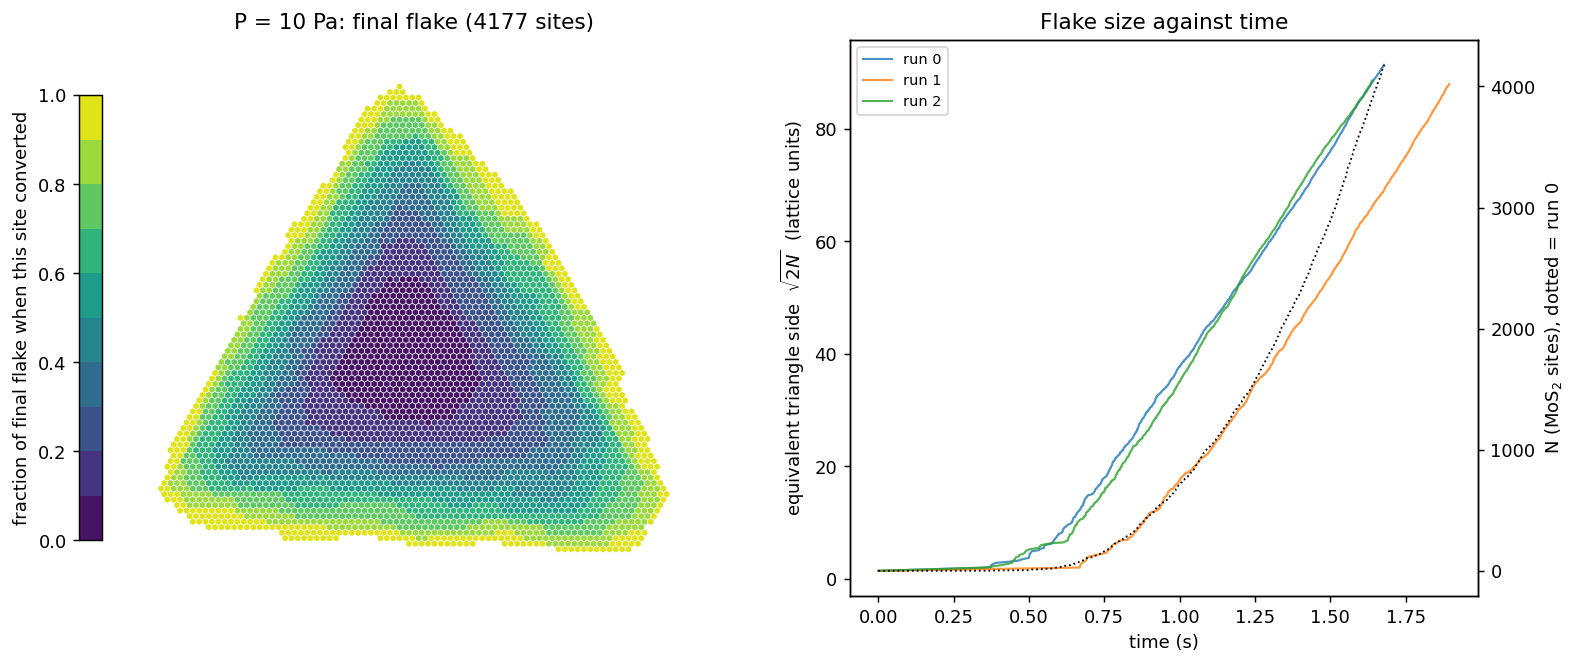

In [ ]:
from IPython.display import Image
Image("results/q1_triangle_growth.png")

![growth at high pressure](results/q1_growth_high_pressure.gif)

## Q2. Equal edge rates: the flake becomes a hexagon

| case | $k_S/k_{Mo}$ | $A_3$ | Mo-edge share |
|---|---|---|---|
| S-edge fast (default) | 5.70 | 0.28 ± 0.01 | 94% |
| smaller difference | 2.39 | 0.17 ± 0.01 | 77% |
| equal edge rates | 1.00 | 0.03 ± 0.01 | 52% |
| Mo-edge fast (reversed) | 0.17 | 0.26 ± 0.01 | 11% |

**Why.** A growing crystal ends up bounded by its **slowest** edges (the kinetic Wulff
construction). A fast edge outruns its neighbours, gets shorter and disappears into a corner. The slow edges
are left behind and get longer. With S-edges fast, the three Mo-edges survive and form a triangle. With equal rates
there is no winner: all six zigzag edges survive and the flake is a **hexagon** ($A_3 \approx 0$, 50/50 edges).
Reversing the rates gives a triangle again, but rotated by 180° and bounded by S-edges. Triangles in experiment
therefore indicate that one edge termination grows much faster than the other, which depends on the S:Mo ratio.

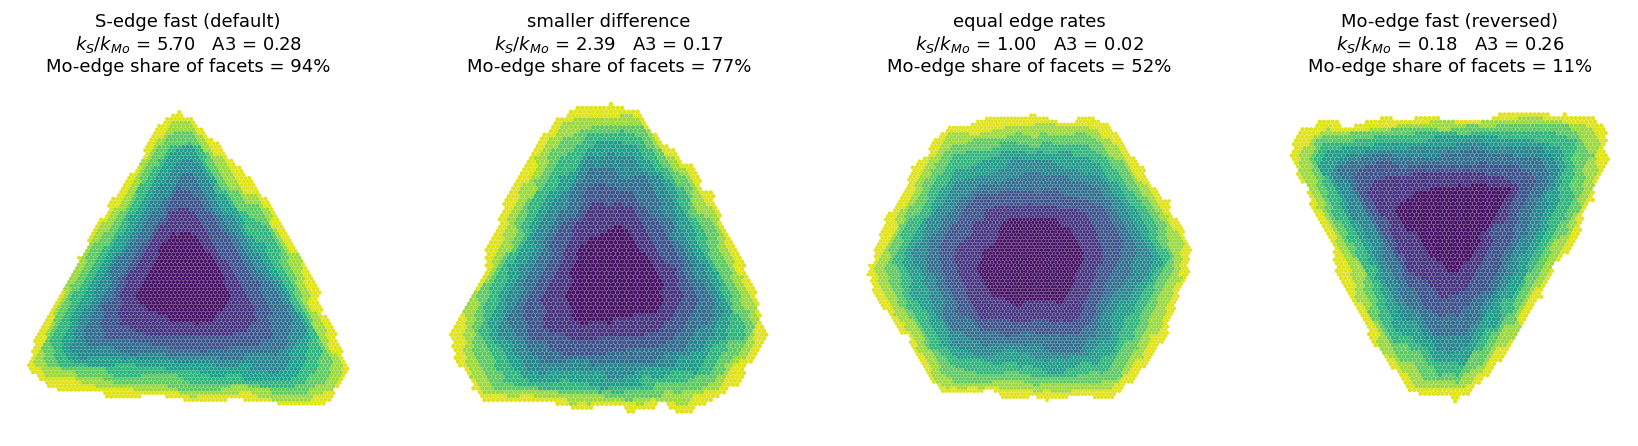

In [ ]:
from IPython.display import Image
Image("results/q2_edge_rates.png")

## Q3. Lowering the sulfur pressure: where does growth stop?

One nucleus, 10 runs per pressure, 200 s growth window:

| P (Pa) | nuclei that grew | median final size | edge speed (sites/s) |
|---|---|---|---|
| 10 | 100% | 3708 | 82.9 |
| 3 | 100% | 3428 | 64.8 |
| 1 | 100% | 3668 | 36.2 |
| 0.6 | 100% | 3630 | 24.3 |
| 0.4 | 90% | 3782 | 16.6 |
| 0.3 | 50% | 1488 | 12.3 |
| 0.25 | 40% | 1 | 9.6 |
| 0.2 | 20% | 1 | 7.3 |
| 0.15 | 10% | 1 | 5.4 |
| 0.1 | 0% | 1 | 0.0 |
| 0.05 | 0% | 1 | 0.0 |

* Down to **0.6 Pa** every nucleus grows into a full triangle. The growth is slower (the edge speed falls
  steeply with P) but the shape is unchanged.
* Between 0.6 and 0.1 Pa it becomes a **lottery**. Some nuclei never get going, but those that do
  grow all the way.
* At **0.1 Pa and below**, no single nucleus grows: the flake stays at 1 site.

So growth stops at **P ≈ 0.1–0.6 Pa** for a single nucleus. Because conversion is irreversible in this
model, "stop" means the rate falls far below 1/(growth window). The transition is sharp anyway: the rate at the
nucleus scales as $P^2$ (two S needed), so a 5× longer window would only move the threshold by √5.

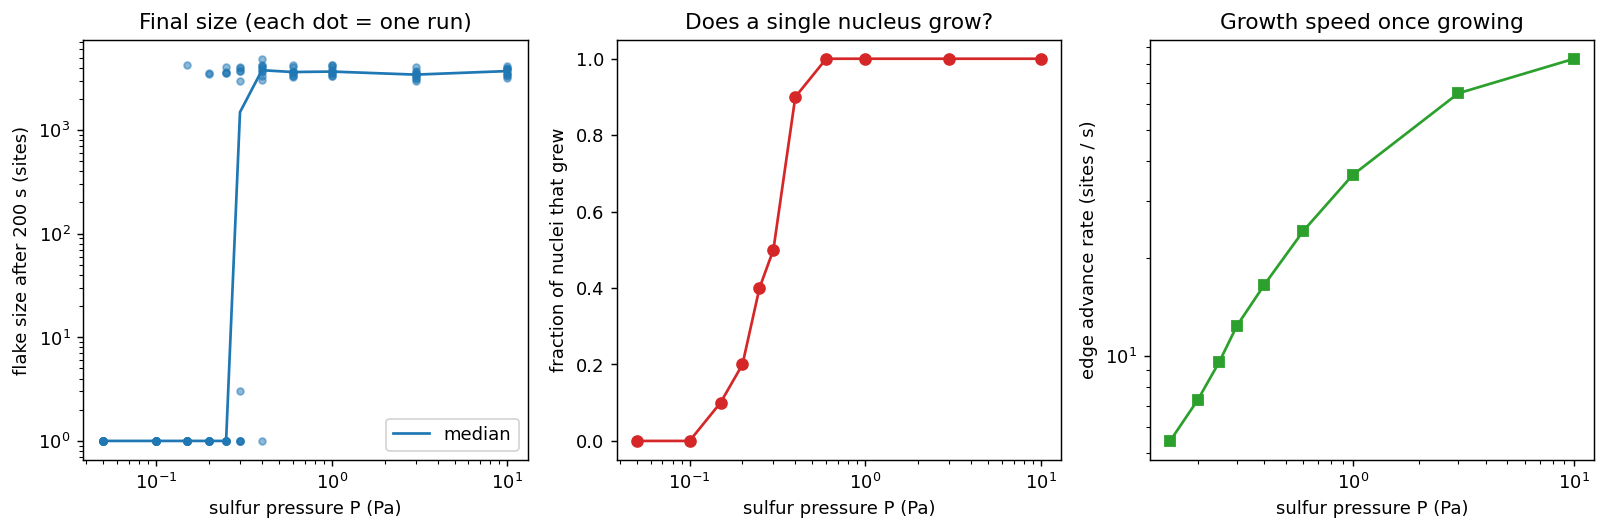

In [ ]:
from IPython.display import Image
Image("results/q3_pressure_sweep.png")

## Q4. Why it stops, and why small flakes are hit hardest

**Desorption wins.** An edge site can only convert while it holds both S atoms. That turns it into a race between
*conversion* and *an S atom leaving*:

| edge site | $k_{des}$ per S (s⁻¹) | $P_{1/2}$ for half-filled slots (Pa) | $k_{conv}$ (s⁻¹) | P(convert before an S leaves) |
|---|---|---|---|---|
| corner / lone nucleus (n=1) | 833 | 8.33 | 0.788 | 4.7e-04 |
| Mo-edge facet (n=2) | 45.8 | 0.458 | 4.49 | 4.7e-02 |
| S-edge facet (n=2) | 45.8 | 0.458 | 25.6 | 2.2e-01 |
| kink (n=3) | 2.52 | 0.0252 | 146 | 9.7e-01 |

At a site touching the flake with only **one** neighbour, an S atom leaves ≈ 800 times per second, while
conversion happens about once per second. At low P the site is almost never full ($\theta^2 \ll 1$),
and when it is full, an S atom leaves first > 99.9% of the time. The effective attachment rate
$k_{conv}\theta(n)^2$ (left panel) falls as $P^2$ and drops below 1/(growth window) first for the
weakly bound sites. In the stalled runs at 0.1 Pa (middle panel), the edge sites around the lone
nucleus lost 118532 S atoms and converted **0** times.

**Why size matters.** Each MoS₂ neighbour raises the desorption barrier by 0.25 eV, so S stays
18× longer per neighbour, and the chance of holding 2 S rises by ≈ 331×.
* A **lone nucleus** offers only $n=1$ sites, the worst case.
* A flake with straight edges offers $n=2$ sites (to start a new row) and $n=3$ kinks (to finish it).
* A larger flake also has longer edges, so there are more places to start a row.

The right panel starts from hexagonal seeds of increasing size. The pressure at which growth stops falls
from ≈0.1–0.6 Pa for a single site to ≈ 0.01–0.02 Pa for 7–37 sites, ≈ 0.007 Pa for 91 sites and
≈ 0.005 Pa for 217 sites. Bigger nuclei keep growing at lower pressure. This is a
**critical nucleus size**: the kinetic version of the Gibbs–Thomson effect. Sharply curved, poorly coordinated
edges lose their sulfur before they can convert.

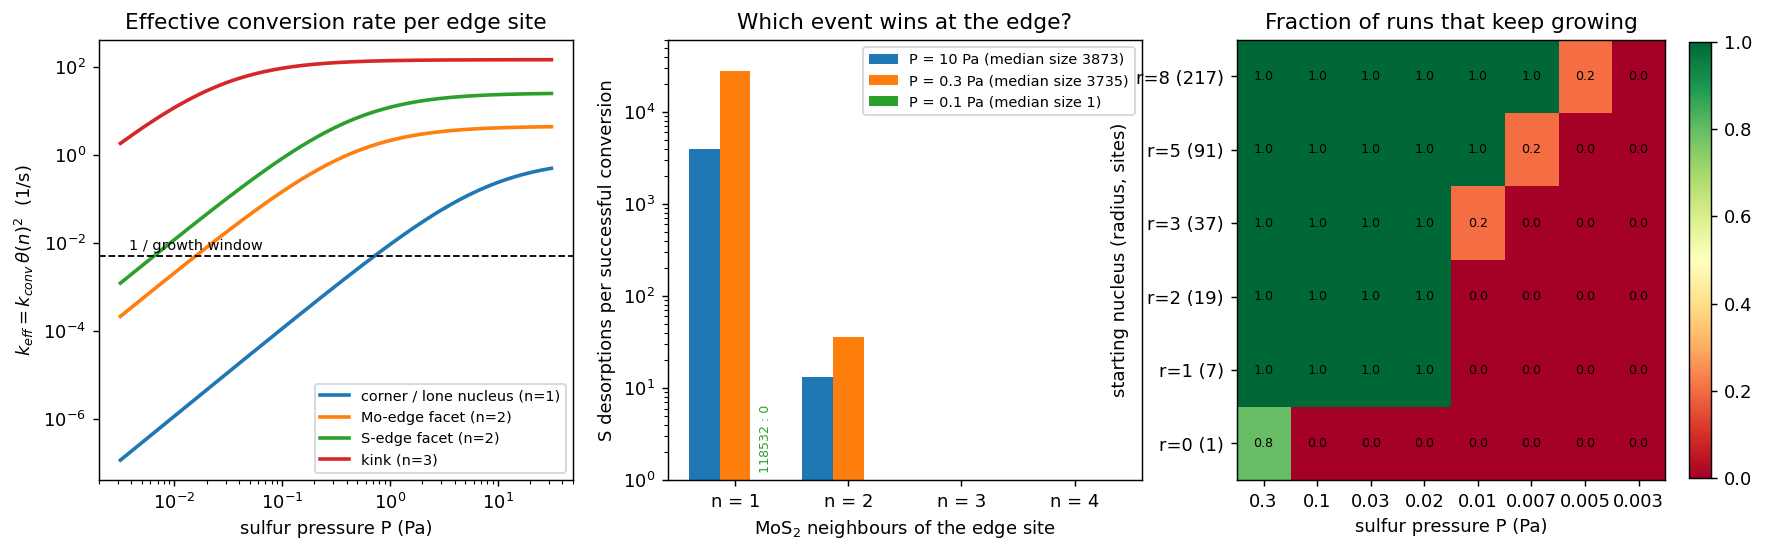

In [ ]:
from IPython.display import Image
Image("results/q4_why_it_stops.png")

## Q5. A second nucleus close to the first, at 0.1 Pa

At 0.1 Pa a lone nucleus never grows (0/10 runs).
Adding a second nucleus at distance *d* (lattice hops):

| d | pairs that grew | median final size |
|---|---|---|
| 1 | 100% | 3682 |
| 2 | 100% | 3476 |
| 3 | 0% | 2 |
| 4 | 0% | 2 |
| 6 | 0% | 2 |

**What happens.** At *d* = 2 the two nuclei share an oxide neighbour (black ring in the figure). That site has
$n = 2$, so its S stays 18× longer and it is full ≈ 200× more often than any site around
a lone nucleus. It converts within tens of seconds and **bridges** the two nuclei. The new 3-site cluster
offers more $n=2$ and $n=3$ sites, so the next conversions are even faster and the pair grows into
**one single triangle**. At *d* = 1 the two nuclei already form a dimer, which works the same way. At *d* ≥ 3 the
nuclei share no neighbour, so each one behaves as a lone nucleus and both stall.

**Why it matters.** A flake that is too small to grow alone becomes supercritical when its edge
sites get extra MoS₂ neighbours from another flake. Neighbouring nuclei cooperate, and this is the
same physics as Q4. In real CVD this favours growth where nuclei are dense (substrate steps, seeds,
defects) and leads to coalescence of nearby nuclei into one larger flake.

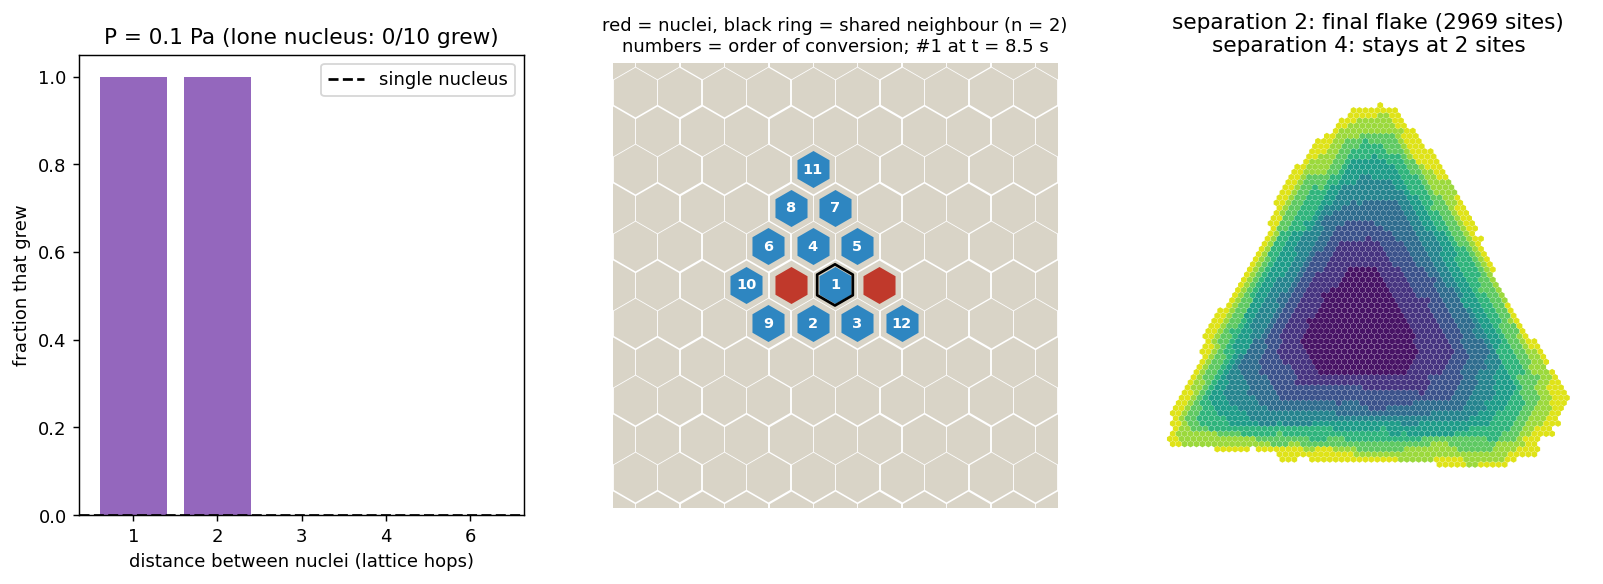

In [ ]:
from IPython.display import Image
Image("results/q5_two_nuclei.png")

![two nuclei](results/q5_two_nuclei.gif)

## What I would improve with more time

1. **Reversibility.** Let MoS₂ edge sites lose S and revert (or let Mo etch away as volatile MoO₃₋ₓ). Then a
   true critical nucleus and an equilibrium shape exist, instead of a "slow enough" kinetic stop.
2. **Sulfur transport.** Model S diffusion on the surface and depletion of S₂ above the flake (boundary layer).
   Couple *P* to the chamber-scale CVD model, so each region of the substrate sees its own local pressure.
3. **Barriers from DFT.** Replace the hand-picked $E$ and $\varepsilon$ with DFT/NEB values for S₂ adsorption,
   desorption and Mo-edge versus S-edge sulfidation, and add temperature sweeps (Arrhenius plots of growth speed).
4. **Mo supply.** Here the Mo is already on the substrate. Real growth also involves MoO₃₋ₓ vapour and
   Mo/S ratio effects, which switch the slow edge and give truncated triangles and hexagons.
5. **Scale and speed.** Use a Numba or C++ engine and bigger lattices (10⁶ sites). Run many nuclei to get size
   distributions and nucleation density versus P, and to see grain boundaries when misoriented flakes meet.